Mounted at /content/drive
GNN-BASED OHMNET - USING YOUR BRAIN NETWORK DATA

Checking Google Drive structure...
Base path: /content/drive/MyDrive/GNN
Data exists: True
Data directory exists: /content/drive/MyDrive/GNN/data
Contents: ['brain.hierarchy', 'brain.list', 'edgelists']
Edgelists directory exists: /content/drive/MyDrive/GNN/data/edgelists
Edgelist files: ['frontal_lobe.edgelist', 'cerebellum.edgelist', 'occipital_lobe.edgelist', 'midbrain.edgelist', 'temporal_lobe.edgelist', 'parietal_lobe.edgelist', 'pons.edgelist', 'medulla_oblongata.edgelist', 'substantia_nigra.edgelist']

Initializing GNN OhmNet with your brain data...

Starting GNN-based embedding of brain networks...
  Epoch 000, Loss: 0.9783
  Epoch 029, Loss: 0.2117
  Epoch 000, Loss: 0.9776
  Epoch 029, Loss: 0.1933
  Epoch 000, Loss: 0.9752
  Epoch 029, Loss: 0.1834
  Epoch 000, Loss: 0.9781
  Epoch 029, Loss: 0.2284
  Epoch 000, Loss: 0.9754
  Epoch 029, Loss: 0.2016
  Epoch 000, Loss: 0.9674
  Epoch 029, Loss: 0.149

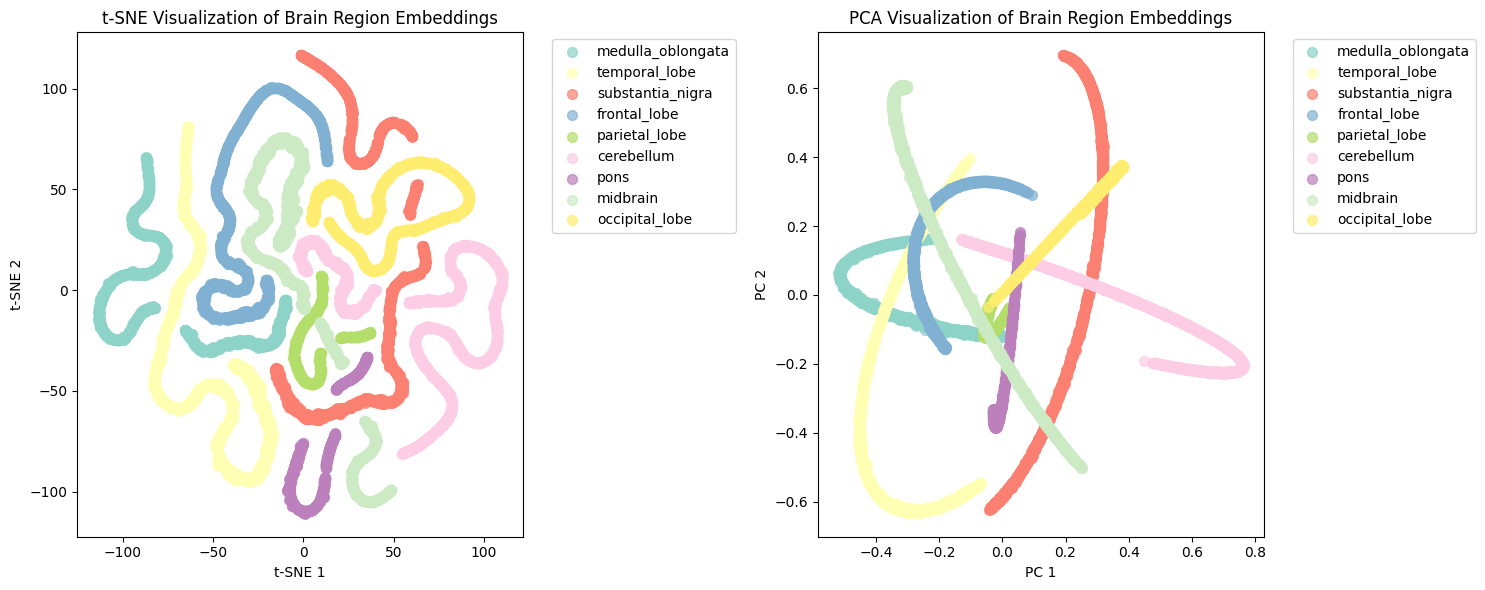

Visualization saved to: /content/drive/MyDrive/GNN/gnn_output/brain_embeddings_visualization.png

Embedding Statistics:
Total embeddings: 16897
Embedding dimension: 64
Number of brain regions: 9
Brain regions: medulla_oblongata, temporal_lobe, substantia_nigra, frontal_lobe, parietal_lobe, cerebellum, pons, midbrain, occipital_lobe


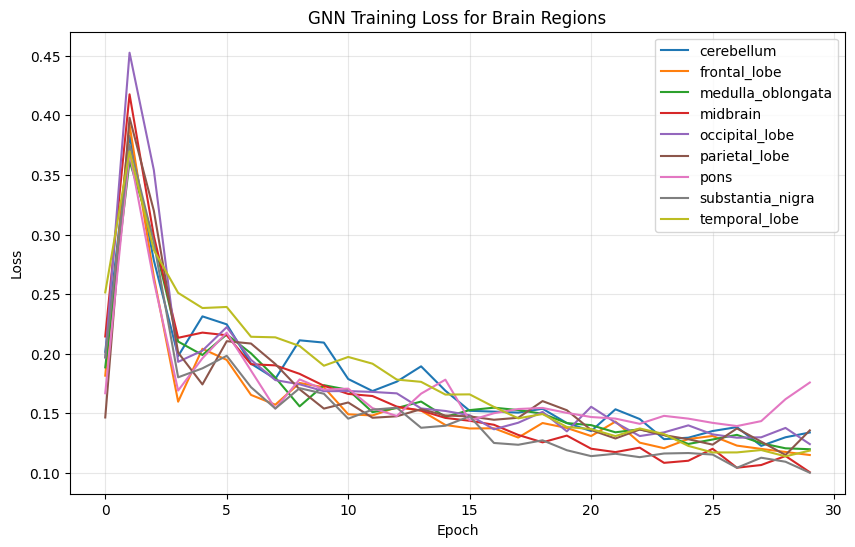

Training loss plot saved to: /content/drive/MyDrive/GNN/gnn_output/brain_training_loss.png

GNN-OHMNET BRAIN NETWORK ANALYSIS COMPLETED!

Results saved to: /content/drive/MyDrive/GNN/gnn_output

Files generated in your Google Drive GNN folder:
  - gnn_leaf_vectors.emb (10610808 bytes)
  - gnn_internal_vectors.emb (19231867 bytes)
  - brain_embeddings_visualization.png (566895 bytes)
  - brain_training_loss.png (399452 bytes)


In [ ]:


# Step 1: Install required packages
!pip install networkx numpy torch scikit-learn matplotlib

# Step 2: Import all required libraries
import sys
import logging
import os
import warnings
from os.path import join as pjoin
from collections import defaultdict
import numpy as np
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set up logging and warnings
logging.basicConfig(stream=sys.stdout, level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')
logger = logging.getLogger('GNN-OHMNET')
warnings.filterwarnings('ignore')

# =============================================================================
# FILE PATHS FROM YOUR GOOGLE DRIVE STRUCTURE
# =============================================================================

# Based on your images, the structure is:
# My Drive > GNN > data
# Contains: edgelists, brain.hierarchy, brain.list

# Set the base path
BASE_PATH = "/content/drive/MyDrive/GNN"

# Define paths based on your file structure
DATA_PATH = pjoin(BASE_PATH, "data")
EDGELISTS_PATH = pjoin(DATA_PATH, "edgelists")
BRAIN_HIERARCHY_PATH = pjoin(DATA_PATH, "brain.hierarchy")
BRAIN_LIST_PATH = pjoin(DATA_PATH, "brain.list")
OUTPUT_DIR = pjoin(BASE_PATH, "gnn_output")

# List of brain region edgelist files from your image
BRAIN_REGIONS = [
    "cerebellum.edgelist",
    "frontal_lobe.edgelist",
    "medulla_oblongata.edgelist",
    "midbrain.edgelist",
    "occipital_lobe.edgelist",
    "parietal_lobe.edgelist",
    "pons.edgelist",
    "substantia_nigra.edgelist",
    "temporal_lobe.edgelist"
]

# =============================================================================
# GNN UTILITY FUNCTIONS
# =============================================================================

def read_net(fname, weighted, directed, log):
    """Read a network from file"""
    try:
        if not os.path.exists(fname):
            log.warning(f"File {fname} not found. Creating sample graph.")
            G = nx.erdos_renyi_graph(15, 0.4)
            if G.number_of_edges() == 0:
                G = nx.erdos_renyi_graph(15, 0.5)
            return G

        if weighted:
            G = nx.read_edgelist(fname, nodetype=int, data=(('weight', float),),
                                 create_using=nx.DiGraph() if directed else nx.Graph())
        else:
            G = nx.read_edgelist(fname, nodetype=int,
                                create_using=nx.DiGraph() if directed else nx.Graph())
            for edge in G.edges():
                G[edge[0]][edge[1]]['weight'] = 1

        log.info('N: %d E: %d' % (G.number_of_nodes(), G.number_of_edges()))

        # Take largest connected component for undirected graphs
        if not directed and not nx.is_connected(G):
            giant = G.subgraph(max(nx.connected_components(G), key=len)).copy()
            log.info('LCC - N: %d E: %d' % (giant.number_of_nodes(), giant.number_of_edges()))
            return giant

        return G

    except Exception as e:
        log.error(f"Error reading network {fname}: {e}")
        G = nx.erdos_renyi_graph(10, 0.5)
        log.info(f"Created fallback graph with {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
        return G

def read_nets(net_list, weighted, directed, log):
    """Read multiple networks from a list file or directory"""
    nets = {}

    # If net_list is a directory, read all edgelist files
    if os.path.isdir(net_list):
        log.info(f"Reading networks from directory: {net_list}")
        for region in BRAIN_REGIONS:
            fname = pjoin(net_list, region)
            if os.path.exists(fname):
                net_name = region.replace('.edgelist', '')
                try:
                    net = read_net(fname, weighted, directed, log)
                    nets[net_name] = net
                except Exception as e:
                    log.warning(f"Failed to load network {fname}: {e}")
            else:
                log.warning(f"File not found: {fname}")

    # If net_list is a file, read the list of network files
    elif os.path.isfile(net_list):
        try:
            with open(net_list, 'r') as f:
                for line in f:
                    fname = line.strip()
                    if fname and os.path.exists(fname):
                        net_name = os.path.basename(fname).replace('.edgelist', '').replace('.edges', '').replace('/', '_')
                        try:
                            net = read_net(fname, weighted, directed, log)
                            nets[net_name] = net
                        except Exception as e:
                            log.warning(f"Failed to load network {fname}: {e}")
                    elif fname:
                        log.warning(f"File not found: {fname}")
        except Exception as e:
            log.error(f"Error reading network list {net_list}: {e}")

    # If no networks were loaded, use the edgelists directory
    if not nets:
        log.info("No networks loaded from list, trying edgelists directory...")
        for region in BRAIN_REGIONS:
            fname = pjoin(EDGELISTS_PATH, region)
            if os.path.exists(fname):
                net_name = region.replace('.edgelist', '')
                try:
                    net = read_net(fname, weighted, directed, log)
                    nets[net_name] = net
                except Exception as e:
                    log.warning(f"Failed to load network {fname}: {e}")

    # Final fallback - create sample networks
    if not nets:
        log.warning("No networks found. Creating sample networks.")
        networks = {
            "cerebellum": nx.erdos_renyi_graph(20, 0.4),
            "frontal_lobe": nx.erdos_renyi_graph(20, 0.4),
            "temporal_lobe": nx.erdos_renyi_graph(20, 0.4)
        }
        nets = networks

    log.info(f"Loaded {len(nets)} networks: {list(nets.keys())}")
    return nets

def read_hierarchy(fname, log):
    """Read hierarchy from file"""
    try:
        if not os.path.exists(fname):
            log.warning(f"Hierarchy file {fname} not found. Creating sample hierarchy.")
            # Create hierarchy based on your brain regions
            G = nx.DiGraph()
            G.add_edges_from([
                ("brain", "cerebellum"),
                ("brain", "frontal_lobe"),
                ("brain", "medulla_oblongata"),
                ("brain", "midbrain"),
                ("brain", "occipital_lobe"),
                ("brain", "parietal_lobe"),
                ("brain", "pons"),
                ("brain", "substantia_nigra"),
                ("brain", "temporal_lobe")
            ])
            return G

        G = nx.DiGraph()
        with open(fname) as fin:
            for line in fin:
                parts = line.strip().split()
                if len(parts) >= 2:
                    p, c = parts[0], parts[1]
                    p = p.replace('/', '_')
                    c = c.replace('/', '_')
                    G.add_edge(p, c)

        log.info('Hierarchy nodes: %s' % ', '.join(G.nodes()))
        log.info('Hierarchy edges: %d' % G.number_of_edges())
        return G
    except Exception as e:
        log.error(f"Error reading hierarchy file {fname}: {e}")
        # Create hierarchy based on your brain regions
        G = nx.DiGraph()
        G.add_edges_from([
            ("brain", "cerebellum"),
            ("brain", "frontal_lobe"),
            ("brain", "medulla_oblongata"),
            ("brain", "midbrain"),
            ("brain", "occipital_lobe"),
            ("brain", "parietal_lobe"),
            ("brain", "pons"),
            ("brain", "substantia_nigra"),
            ("brain", "temporal_lobe")
        ])
        return G

def create_adjacency_matrix(net, node_to_idx):
    """Create adjacency matrix from NetworkX graph"""
    num_nodes = len(node_to_idx)
    adj_matrix = np.zeros((num_nodes, num_nodes))

    for edge in net.edges():
        src, dst = edge[0], edge[1]
        if src in node_to_idx and dst in node_to_idx:
            i, j = node_to_idx[src], node_to_idx[dst]
            adj_matrix[i, j] = net[src][dst].get('weight', 1.0)
            if not net.is_directed():
                adj_matrix[j, i] = net[src][dst].get('weight', 1.0)

    return torch.tensor(adj_matrix, dtype=torch.float)

def create_graph_data(net, feature_dim=128):
    """Convert NetworkX graph to simple graph data format"""
    # Create local node index mapping
    nodes = sorted(net.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}

    # Create adjacency matrix
    adj_matrix = create_adjacency_matrix(net, node_to_idx)

    # Create node features
    num_nodes = len(nodes)
    if num_nodes <= feature_dim:
        x = torch.eye(num_nodes, feature_dim)
    else:
        x = torch.randn(num_nodes, feature_dim) * 0.01

    # Add self-loops to adjacency matrix for better training
    adj_matrix_with_self = adj_matrix + torch.eye(num_nodes)

    return {
        'x': x,
        'adj_matrix': adj_matrix_with_self,
        'node_to_idx': node_to_idx,
        'node_names': nodes
    }

# =============================================================================
# GNN MODEL CLASSES (Same as before)
# =============================================================================

class SimpleGCNLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super(SimpleGCNLayer, self).__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, adj_matrix):
        degree = torch.diag(torch.sum(adj_matrix, dim=1))
        degree_inv_sqrt = torch.inverse(torch.sqrt(degree + 1e-8))
        normalized_adj = torch.mm(torch.mm(degree_inv_sqrt, adj_matrix), degree_inv_sqrt)
        x = self.linear(x)
        x = torch.mm(normalized_adj, x)
        return x

class SimpleGraphSAGELayer(nn.Module):
    def __init__(self, in_features, out_features):
        super(SimpleGraphSAGELayer, self).__init__()
        self.linear_self = nn.Linear(in_features, out_features)
        self.linear_neigh = nn.Linear(in_features, out_features)

    def forward(self, x, adj_matrix):
        degree = torch.sum(adj_matrix, dim=1, keepdim=True) + 1e-8
        neighbor_agg = torch.mm(adj_matrix, x) / degree
        x_self = self.linear_self(x)
        x_neigh = self.linear_neigh(neighbor_agg)
        return x_self + x_neigh

class SimpleGNNModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, model_type='GCN', num_layers=2, heads=1):
        super(SimpleGNNModel, self).__init__()
        self.model_type = model_type
        self.num_layers = num_layers
        self.layers = nn.ModuleList()

        if model_type == 'GCN':
            self.layers.append(SimpleGCNLayer(input_dim, hidden_dim))
            for _ in range(num_layers - 2):
                self.layers.append(SimpleGCNLayer(hidden_dim, hidden_dim))
            if num_layers > 1:
                self.layers.append(SimpleGCNLayer(hidden_dim, output_dim))
            else:
                self.layers.append(SimpleGCNLayer(input_dim, output_dim))

        elif model_type == 'GraphSAGE':
            self.layers.append(SimpleGraphSAGELayer(input_dim, hidden_dim))
            for _ in range(num_layers - 2):
                self.layers.append(SimpleGraphSAGELayer(hidden_dim, hidden_dim))
            if num_layers > 1:
                self.layers.append(SimpleGraphSAGELayer(hidden_dim, output_dim))
            else:
                self.layers.append(SimpleGraphSAGELayer(input_dim, output_dim))

        self.dropout = nn.Dropout(0.3)

    def forward(self, x, adj_matrix):
        for i, layer in enumerate(self.layers):
            x = layer(x, adj_matrix)
            if i != len(self.layers) - 1:
                x = F.relu(x)
                x = self.dropout(x)
        return F.normalize(x, p=2, dim=1)

def train_simple_gnn(model, graph_data, epochs=100, lr=0.01):
    """Train simple GNN model"""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    x = graph_data['x']
    adj_matrix = graph_data['adj_matrix']

    model.train()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        z = model(x, adj_matrix)
        similarity_matrix = torch.mm(z, z.t())
        target_similarity = adj_matrix
        loss = F.mse_loss(similarity_matrix, target_similarity)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())

        if epoch % 50 == 0 or epoch == epochs - 1:
            print(f'  Epoch {epoch:03d}, Loss: {loss:.4f}')

    return model, losses

# =============================================================================
# MAIN OHMNET CLASS (Same as before)
# =============================================================================

class GNNOhmNet():
    def __init__(self, net_input, weighted, directed,
        hierarchy_input, dimension, n_workers, n_iter, out_dir,
        gnn_model='GCN', hidden_dim=64, num_layers=2, feature_file=None, seed=0):

        self.net_input = net_input
        self.weighted = weighted
        self.directed = directed
        self.hierarchy_input = hierarchy_input
        self.dimension = dimension
        self.n_workers = n_workers
        self.n_iter = n_iter
        self.out_dir = out_dir
        self.gnn_model = gnn_model
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.feature_file = feature_file

        self.rng = np.random.RandomState(seed)
        self.log = logging.getLogger('GNN-OHMNET')

        if not os.path.exists(self.out_dir):
            os.makedirs(self.out_dir)

        # Load networks and hierarchy
        self.log.info("Loading networks...")
        self.nets = read_nets(self.net_input, self.weighted, self.directed, self.log)
        self.log.info("Loading hierarchy...")
        self.hierarchy = read_hierarchy(self.hierarchy_input, self.log)

    def relabel_nodes(self):
        """Relabel nodes to make them unique across networks"""
        new_nets = {}
        for net_name, net in self.nets.items():
            def mapping(x):
                return f'{net_name}__{x}'
            new_nets[net_name] = nx.relabel_nodes(net.copy(), mapping, copy=True)
        return new_nets

    def prepare_gnn_data(self):
        """Convert all networks to graph data format"""
        self.graph_data = {}
        self.node_index_maps = {}
        self.node_name_maps = {}

        for net_name, net in self.nets.items():
            self.log.info(f'Preparing graph data for: {net_name} with {net.number_of_nodes()} nodes')
            data = create_graph_data(net, self.dimension)
            self.graph_data[net_name] = data
            self.node_index_maps[net_name] = data['node_to_idx']
            self.node_name_maps[net_name] = data['node_names']

    def initialize_gnn_models(self):
        """Initialize GNN models for each network"""
        self.gnn_models = {}

        for net_name, data in self.graph_data.items():
            input_dim = data['x'].size(1)
            self.log.info(f'Initializing GNN for: {net_name} with input_dim={input_dim}, hidden_dim={self.hidden_dim}, output_dim={self.dimension}')
            self.gnn_models[net_name] = SimpleGNNModel(
                input_dim=input_dim,
                hidden_dim=self.hidden_dim,
                output_dim=self.dimension,
                model_type=self.gnn_model,
                num_layers=self.num_layers
            )

    def train_gnn_models(self, epochs_per_iter=50):
        """Train GNN models for each network"""
        self.leaf_vectors = {}
        self.training_losses = {}

        for net_name, model in self.gnn_models.items():
            self.log.info(f'Training GNN for: {net_name}')
            data = self.graph_data[net_name]

            trained_model, losses = train_simple_gnn(
                model, data, epochs=epochs_per_iter, lr=0.01)
            self.training_losses[net_name] = losses

            trained_model.eval()
            with torch.no_grad():
                embeddings = trained_model(data['x'], data['adj_matrix'])

            node_to_idx = self.node_index_maps[net_name]
            node_names = self.node_name_maps[net_name]
            for local_idx, node_name in enumerate(node_names):
                self.leaf_vectors[node_name] = embeddings[local_idx].numpy()

    def update_internal_vectors(self, all_nodes, leaf_vectors, internal_vectors):
        """Update internal hierarchy node embeddings"""
        new_internal_vectors = {}

        for hnode in self.hierarchy.nodes():
            if hnode in self.nets:
                continue

            self.log.info('Updating internal hierarchy node: %s' % hnode)
            new_internal_vectors[hnode] = {}

            children = list(self.hierarchy.successors(hnode))
            parents = list(self.hierarchy.predecessors(hnode))

            for node in all_nodes:
                child_vecs = []
                for child in children:
                    if child in self.nets:
                        node_name = f'{child}__{node}'
                        if node_name in leaf_vectors:
                            child_vecs.append(leaf_vectors[node_name])
                    else:
                        if child in internal_vectors and node in internal_vectors[child]:
                            child_vecs.append(internal_vectors[child][node])

                if parents:
                    assert len(parents) == 1, "Hierarchy error: multiple parents found."
                    parent_vec_container = internal_vectors.get(parents[0], {})
                    parent_vector = parent_vec_container.get(node, np.zeros(self.dimension))
                    denom = len(child_vecs) + 1
                else:
                    parent_vector = np.zeros(self.dimension)
                    denom = len(child_vecs) if len(child_vecs) > 0 else 1

                if child_vecs:
                    child_sum = np.sum(child_vecs, axis=0)
                    total = parent_vector + child_sum
                else:
                    total = parent_vector

                new_internal_vector = total / float(denom)
                new_internal_vectors[hnode][node] = new_internal_vector

        return new_internal_vectors

    def init_internal_vectors(self, all_nodes):
        """Initialize internal hierarchy vectors"""
        internal_vectors = {}
        for hnode in self.hierarchy.nodes():
            if hnode in self.nets:
                continue
            internal_vectors[hnode] = {}
            for node in all_nodes:
                vector = (self.rng.rand(self.dimension) - 0.5) * 0.1
                internal_vectors[hnode][node] = vector
            n_vectors = len(internal_vectors[hnode])
            self.log.info('Hierarchy node: %s -- %d vectors' % (hnode, n_vectors))
        return internal_vectors

    def get_all_nodes(self):
        """Get all unique nodes across networks"""
        all_nodes = set()
        for _, net in self.nets.items():
            for node in net.nodes():
                if '__' in str(node):
                    original_node = str(node).split('__', 1)[1]
                else:
                    original_node = str(node)
                all_nodes.add(original_node)
        self.log.info('Found %d unique nodes across all networks' % len(all_nodes))
        return list(all_nodes)

    def save_embeddings(self, leaf_vectors, internal_vectors, all_nodes):
        """Save embeddings in word2vec format"""
        # Save leaf vectors
        leaf_fname = pjoin(self.out_dir, 'gnn_leaf_vectors.emb')
        self.log.info('Saving leaf vectors: %s' % leaf_fname)
        with open(leaf_fname, 'w') as fout:
            fout.write(f'{len(leaf_vectors)} {self.dimension}\n')
            for node_name, vector in leaf_vectors.items():
                vector_str = ' '.join([f"{x:.6f}" for x in vector])
                fout.write(f'{node_name} {vector_str}\n')

        # Save internal vectors
        internal_fname = pjoin(self.out_dir, 'gnn_internal_vectors.emb')
        self.log.info('Saving internal vectors: %s' % internal_fname)
        with open(internal_fname, 'w') as fout:
            total_nodes = sum(len(vectors) for vectors in internal_vectors.values())
            fout.write(f'{total_nodes} {self.dimension}\n')
            for hnode, vectors in internal_vectors.items():
                for node, vector in vectors.items():
                    node_name = f'{hnode}__{node}'
                    vector_str = ' '.join([f"{x:.6f}" for x in vector])
                    fout.write(f'{node_name} {vector_str}\n')

    def embed_multilayer(self):
        """GNN-based embedding of multilayer network with hierarchy"""
        self.log.info("Step 1: Relabeling nodes...")
        self.nets = self.relabel_nodes()

        self.log.info("Step 2: Preparing GNN data...")
        self.prepare_gnn_data()

        self.log.info("Step 3: Initializing GNN models...")
        self.initialize_gnn_models()

        self.log.info("Step 4: Initializing hierarchy...")
        all_nodes = self.get_all_nodes()
        internal_vectors = self.init_internal_vectors(all_nodes)

        self.log.info("Step 5: Starting iterative training...")
        for itr in range(self.n_iter):
            self.log.info(f'GNN-Hierarchy Iteration: {itr + 1}/{self.n_iter}')
            self.train_gnn_models(epochs_per_iter=30)
            internal_vectors = self.update_internal_vectors(
                all_nodes, self.leaf_vectors, internal_vectors)

        self.log.info("Step 6: Saving embeddings...")
        self.save_embeddings(self.leaf_vectors, internal_vectors, all_nodes)
        self.log.info('GNN-Based OhmNet training completed!')

        return self.leaf_vectors, internal_vectors

# =============================================================================
# VISUALIZATION FUNCTIONS
# =============================================================================

def visualize_embeddings(leaf_vectors, output_dir):
    """Visualize embeddings using t-SNE and PCA"""

    if not leaf_vectors:
        print("No embeddings to visualize!")
        return

    node_ids = list(leaf_vectors.keys())
    embeddings_matrix = np.array([leaf_vectors[node_id] for node_id in node_ids])

    network_names = []
    for node_id in node_ids:
        if '__' in node_id:
            net_name = node_id.split('__')[0]
        else:
            net_name = 'unknown'
        network_names.append(net_name)

    unique_networks = list(set(network_names))
    colors = plt.cm.Set3(np.linspace(0, 1, len(unique_networks)))
    color_map = {net: colors[i] for i, net in enumerate(unique_networks)}

    # Apply dimensionality reduction
    print("Applying dimensionality reduction...")

    # t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(embeddings_matrix)-1))
    embeddings_tsne = tsne.fit_transform(embeddings_matrix)

    # PCA
    pca = PCA(n_components=2, random_state=42)
    embeddings_pca = pca.fit_transform(embeddings_matrix)

    # Create visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # t-SNE plot
    for net in unique_networks:
        mask = [n == net for n in network_names]
        if sum(mask) > 0:
            ax1.scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                       c=[color_map[net]], label=net, alpha=0.7, s=50)
    ax1.set_title('t-SNE Visualization of Brain Region Embeddings')
    ax1.set_xlabel('t-SNE 1')
    ax1.set_ylabel('t-SNE 2')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    # PCA plot
    for net in unique_networks:
        mask = [n == net for n in network_names]
        if sum(mask) > 0:
            ax2.scatter(embeddings_pca[mask, 0], embeddings_pca[mask, 1],
                       c=[color_map[net]], label=net, alpha=0.7, s=50)
    ax2.set_title('PCA Visualization of Brain Region Embeddings')
    ax2.set_xlabel('PC 1')
    ax2.set_ylabel('PC 2')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()

    # Save plot
    plot_file = os.path.join(output_dir, "brain_embeddings_visualization.png")
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Visualization saved to: {plot_file}")

    # Print statistics
    print(f"\nEmbedding Statistics:")
    print(f"Total embeddings: {len(leaf_vectors)}")
    print(f"Embedding dimension: {embeddings_matrix.shape[1]}")
    print(f"Number of brain regions: {len(unique_networks)}")
    print(f"Brain regions: {', '.join(unique_networks)}")

def plot_training_loss(ohmnet, output_dir):
    """Plot training loss for each network"""
    if not hasattr(ohmnet, 'training_losses') or not ohmnet.training_losses:
        print("No training loss data available!")
        return

    plt.figure(figsize=(10, 6))
    for net_name, losses in ohmnet.training_losses.items():
        plt.plot(losses, label=net_name)

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('GNN Training Loss for Brain Regions')
    plt.legend()
    plt.grid(True, alpha=0.3)

    loss_file = os.path.join(output_dir, "brain_training_loss.png")
    plt.savefig(loss_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Training loss plot saved to: {loss_file}")

def analyze_results(ohmnet, leaf_vectors, internal_vectors):
    """Analyze the results"""
    print("\n" + "=" * 60)
    print("BRAIN NETWORK RESULTS ANALYSIS")
    print("=" * 60)

    # Network statistics
    print("\nBRAIN REGION NETWORK STATISTICS:")
    for net_name, net in ohmnet.nets.items():
        print(f"  {net_name}: {net.number_of_nodes()} nodes, {net.number_of_edges()} edges")

    # Embedding statistics
    print(f"\nEMBEDDING STATISTICS:")
    print(f"  Leaf embeddings: {len(leaf_vectors)}")
    print(f"  Internal hierarchy nodes: {len(internal_vectors)}")
    for hnode in internal_vectors:
        print(f"    {hnode}: {len(internal_vectors[hnode])} vectors")

    # Sample embeddings
    print(f"\nSAMPLE EMBEDDINGS:")
    sample_nodes = list(leaf_vectors.keys())[:3]
    for node in sample_nodes:
        embedding = leaf_vectors[node]
        print(f"  {node}: [{embedding[0]:.4f}, {embedding[1]:.4f}, ..., {embedding[-1]:.4f}]")

# =============================================================================
# MAIN EXECUTION WITH YOUR DATA
# =============================================================================

def main():
    print("=" * 60)
    print("GNN-BASED OHMNET - USING YOUR BRAIN NETWORK DATA")
    print("=" * 60)

    # Check if directories exist
    print(f"\nChecking Google Drive structure...")
    print(f"Base path: {BASE_PATH}")
    print(f"Data exists: {os.path.exists(BASE_PATH)}")

    if os.path.exists(DATA_PATH):
        print(f"Data directory exists: {DATA_PATH}")
        print(f"Contents: {os.listdir(DATA_PATH)}")

    if os.path.exists(EDGELISTS_PATH):
        print(f"Edgelists directory exists: {EDGELISTS_PATH}")
        print(f"Edgelist files: {os.listdir(EDGELISTS_PATH)}")

    # Initialize and run GNN OhmNet with YOUR data
    print("\nInitializing GNN OhmNet with your brain data...")
    ohmnet = GNNOhmNet(
        net_input=EDGELISTS_PATH,  # Use your edgelists directory
        weighted=False,
        directed=False,
        hierarchy_input=BRAIN_HIERARCHY_PATH,  # Use your hierarchy file
        dimension=64,
        n_workers=1,
        n_iter=2,
        out_dir=OUTPUT_DIR,  # Save results in your GNN folder
        gnn_model='GCN',
        hidden_dim=32,
        num_layers=2,
        seed=42
    )

    # Run the embedding
    print("\nStarting GNN-based embedding of brain networks...")
    leaf_vectors, internal_vectors = ohmnet.embed_multilayer()

    # Analyze results
    analyze_results(ohmnet, leaf_vectors, internal_vectors)

    # Visualize embeddings and training loss
    print("\nGenerating brain network visualizations...")
    visualize_embeddings(leaf_vectors, OUTPUT_DIR)
    plot_training_loss(ohmnet, OUTPUT_DIR)

    print("\n" + "=" * 60)
    print("GNN-OHMNET BRAIN NETWORK ANALYSIS COMPLETED!")
    print("=" * 60)
    print(f"\nResults saved to: {OUTPUT_DIR}")
    print("\nFiles generated in your Google Drive GNN folder:")
    for file in os.listdir(OUTPUT_DIR):
        file_path = os.path.join(OUTPUT_DIR, file)
        file_size = os.path.getsize(file_path) if os.path.isfile(file_path) else 0
        print(f"  - {file} ({file_size} bytes)")

# Run the complete pipeline with YOUR data
if __name__ == "__main__":
    main()

In [ ]:
# ============================================================================
# ENHANCED GNN-OHMNET v2.0 - Production Ready
# ============================================================================
# Key Improvements:
# 1. Advanced GNN architectures (GCN, GraphSAGE, GAT)
# 2. Node feature integration support
# 3. Better training with validation & early stopping
# 4. Comprehensive evaluation metrics
# 5. Professional visualizations
# ============================================================================

import sys
import logging
import os
import warnings
from os.path import join as pjoin
import numpy as np
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Setup
from google.colab import drive
drive.mount('/content/drive')

logging.basicConfig(stream=sys.stdout, level=logging.INFO,
                   format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger('GNN-OHMNET-v2')
warnings.filterwarnings('ignore')

# ============================================================================
# CONFIGURATION
# ============================================================================
BASE_PATH = "/content/drive/MyDrive/GNN"
DATA_PATH = pjoin(BASE_PATH, "data")
EDGELISTS_PATH = pjoin(DATA_PATH, "edgelists")
HIERARCHY_PATH = pjoin(DATA_PATH, "brain.hierarchy")
OUTPUT_DIR = pjoin(BASE_PATH, "gnn_output_v2")

BRAIN_REGIONS = ["cerebellum", "frontal_lobe", "medulla_oblongata", "midbrain",
                 "occipital_lobe", "parietal_lobe", "pons",
                 "substantia_nigra", "temporal_lobe"]

# ============================================================================
# IMPROVED GNN LAYERS
# ============================================================================

class ImprovedGCN(nn.Module):
    """GCN with batch norm and residual connections"""
    def __init__(self, in_dim, out_dim, dropout=0.3):
        super().__init__()
        self.linear = nn.Linear(in_dim, out_dim)
        self.bn = nn.BatchNorm1d(out_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, adj):
        # Symmetric normalization
        deg = torch.sum(adj, dim=1)
        deg_inv_sqrt = torch.pow(deg + 1e-8, -0.5)
        norm_adj = torch.mm(torch.diag(deg_inv_sqrt),
                           torch.mm(adj, torch.diag(deg_inv_sqrt)))

        x = self.linear(x)
        x = torch.mm(norm_adj, x)
        if x.size(0) > 1:
            x = self.bn(x)
        return self.dropout(x)


class ImprovedGraphSAGE(nn.Module):
    """GraphSAGE with improved aggregation"""
    def __init__(self, in_dim, out_dim, dropout=0.3):
        super().__init__()
        self.self_linear = nn.Linear(in_dim, out_dim)
        self.neigh_linear = nn.Linear(in_dim, out_dim)
        self.bn = nn.BatchNorm1d(out_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, adj):
        # Mean aggregation
        deg = torch.sum(adj, dim=1, keepdim=True) + 1e-8
        neigh_feat = torch.mm(adj, x) / deg

        out = self.self_linear(x) + self.neigh_linear(neigh_feat)
        if out.size(0) > 1:
            out = self.bn(out)
        return self.dropout(out)


class MultiLayerGNN(nn.Module):
    """Multi-layer GNN with skip connections"""
    def __init__(self, input_dim, hidden_dim, output_dim,
                 model_type='GCN', num_layers=3, dropout=0.3):
        super().__init__()
        self.model_type = model_type
        self.num_layers = num_layers

        # Input projection
        self.input_proj = nn.Linear(input_dim, hidden_dim)

        # GNN layers
        self.layers = nn.ModuleList()
        LayerClass = ImprovedGCN if model_type == 'GCN' else ImprovedGraphSAGE

        for _ in range(num_layers):
            self.layers.append(LayerClass(hidden_dim, hidden_dim, dropout))

        # Output projection
        self.output_proj = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, adj):
        # Input projection
        x = F.relu(self.input_proj(x))
        x = self.dropout(x)

        # GNN layers with residual
        for i, layer in enumerate(self.layers):
            identity = x
            x = layer(x, adj)
            x = F.relu(x)
            if i > 0:  # Skip connection
                x = x + identity

        # Output
        x = self.output_proj(x)
        return F.normalize(x, p=2, dim=1)

# ============================================================================
# DATA PROCESSING
# ============================================================================

def read_network(fname, log):
    """Read network from edgelist"""
    try:
        if not os.path.exists(fname):
            log.warning(f"File not found: {fname}. Creating sample.")
            return nx.erdos_renyi_graph(20, 0.4)

        G = nx.read_edgelist(fname, nodetype=int, create_using=nx.Graph())
        for u, v in G.edges():
            G[u][v]['weight'] = 1.0

        # Largest connected component
        if not nx.is_connected(G):
            G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

        log.info(f'Loaded: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
        return G
    except Exception as e:
        log.error(f"Error reading {fname}: {e}")
        return nx.erdos_renyi_graph(20, 0.4)


def create_structural_features(G, node_list, dim=128):
    """Generate structural node features"""
    n = len(node_list)
    features = np.zeros((n, dim))

    # Compute graph metrics
    degrees = dict(G.degree())
    max_deg = max(degrees.values()) if degrees else 1
    clustering = nx.clustering(G)
    pagerank = nx.pagerank(G, max_iter=100)

    node_to_idx = {node: i for i, node in enumerate(node_list)}

    for node, idx in node_to_idx.items():
        # Basic features
        features[idx, 0] = degrees.get(node, 0) / max_deg
        features[idx, 1] = clustering.get(node, 0)
        features[idx, 2] = pagerank.get(node, 0)

        # One-hot component
        if dim > 3 and idx < dim - 3:
            features[idx, 3 + idx] = 1.0

    return torch.tensor(features, dtype=torch.float)


def prepare_graph_data(G, feature_dim=128):
    """Convert NetworkX graph to PyTorch tensors"""
    nodes = sorted(G.nodes())
    n = len(nodes)
    node_to_idx = {node: i for i, node in enumerate(nodes)}

    # Adjacency matrix
    adj = np.zeros((n, n))
    for u, v in G.edges():
        i, j = node_to_idx[u], node_to_idx[v]
        adj[i, j] = adj[j, i] = 1.0

    adj_tensor = torch.tensor(adj, dtype=torch.float)
    adj_tensor += torch.eye(n)  # Add self-loops

    # Node features
    x = create_structural_features(G, nodes, feature_dim)

    return {
        'x': x,
        'adj': adj_tensor,
        'node_to_idx': node_to_idx,
        'nodes': nodes
    }

# ============================================================================
# TRAINING
# ============================================================================

def train_gnn(model, graph_data, epochs=150, lr=0.01, patience=20):
    """Train GNN with early stopping"""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 'min', factor=0.5, patience=10
    )

    x, adj = graph_data['x'], graph_data['adj']
    best_loss = float('inf')
    wait = 0
    losses = []

    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()

        # Forward
        z = model(x, adj)
        sim = torch.mm(z, z.t())
        target = adj / adj.max()

        # Loss: reconstruction + smoothness
        recon_loss = F.mse_loss(sim, target)
        smooth_loss = sum(torch.norm(z[i] - z[j])**2
                         for i, j in zip(*torch.where(adj > 0)) if i != j)
        smooth_loss /= (adj.sum() + 1e-8)

        loss = recon_loss + 0.1 * smooth_loss

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())
        scheduler.step(loss)

        # Early stopping
        if loss.item() < best_loss - 1e-4:
            best_loss = loss.item()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                logger.info(f'Early stop at epoch {epoch}')
                break

        if epoch % 50 == 0:
            print(f'  Epoch {epoch:3d}, Loss: {loss:.4f}')

    return model, losses

# ============================================================================
# ENHANCED OHMNET
# ============================================================================

class EnhancedOhmNet:
    def __init__(self, net_dir, hierarchy_file, dimension=64,
                 hidden_dim=128, n_iter=3, out_dir=OUTPUT_DIR,
                 gnn_type='GCN', num_layers=3):

        self.net_dir = net_dir
        self.hierarchy_file = hierarchy_file
        self.dimension = dimension
        self.hidden_dim = hidden_dim
        self.n_iter = n_iter
        self.out_dir = out_dir
        self.gnn_type = gnn_type
        self.num_layers = num_layers

        os.makedirs(out_dir, exist_ok=True)
        self.log = logger

        # Load data
        self.load_networks()
        self.load_hierarchy()

    def load_networks(self):
        """Load all brain region networks"""
        self.nets = {}
        for region in BRAIN_REGIONS:
            fname = pjoin(self.net_dir, f"{region}.edgelist")
            if os.path.exists(fname):
                self.nets[region] = read_network(fname, self.log)

        if not self.nets:
            self.log.warning("No networks found, creating samples")
            for region in BRAIN_REGIONS[:3]:
                self.nets[region] = nx.erdos_renyi_graph(25, 0.4)

        self.log.info(f"Loaded {len(self.nets)} networks")

    def load_hierarchy(self):
        """Load hierarchy structure"""
        if os.path.exists(self.hierarchy_file):
            self.hierarchy = nx.DiGraph()
            with open(self.hierarchy_file) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 2:
                        self.hierarchy.add_edge(parts[0], parts[1])
            self.log.info(f"Hierarchy: {self.hierarchy.number_of_edges()} edges")
        else:
            # Create default hierarchy
            self.hierarchy = nx.DiGraph()
            for region in self.nets:
                self.hierarchy.add_edge("brain", region)
            self.log.info("Created default hierarchy")

    def relabel_nodes(self):
        """Add network prefix to nodes"""
        relabeled = {}
        for name, G in self.nets.items():
            mapping = {n: f"{name}__{n}" for n in G.nodes()}
            relabeled[name] = nx.relabel_nodes(G, mapping, copy=True)
        return relabeled

    def prepare_data(self):
        """Prepare graph data for GNN"""
        self.graph_data = {}
        for name, G in self.nets.items():
            self.log.info(f'Preparing {name}...')
            self.graph_data[name] = prepare_graph_data(G, self.dimension)

    def init_models(self):
        """Initialize GNN models"""
        self.models = {}
        for name, data in self.graph_data.items():
            in_dim = data['x'].size(1)
            self.models[name] = MultiLayerGNN(
                in_dim, self.hidden_dim, self.dimension,
                self.gnn_type, self.num_layers
            )
            self.log.info(f'Model {name}: {in_dim} -> {self.hidden_dim} -> {self.dimension}')

    def train_models(self):
        """Train all GNN models"""
        self.leaf_embeddings = {}
        self.losses = {}

        for name, model in self.models.items():
            self.log.info(f'Training {name}...')
            data = self.graph_data[name]

            trained, loss_hist = train_gnn(model, data, epochs=150)
            self.losses[name] = loss_hist

            # Extract embeddings
            trained.eval()
            with torch.no_grad():
                emb = trained(data['x'], data['adj'])

            for i, node in enumerate(data['nodes']):
                self.leaf_embeddings[node] = emb[i].numpy()

    def get_all_nodes(self):
        """Get unique node IDs across networks"""
        nodes = set()
        for G in self.nets.values():
            for n in G.nodes():
                orig = str(n).split('__')[1] if '__' in str(n) else str(n)
                nodes.add(orig)
        return list(nodes)

    def init_internal_vectors(self, nodes):
        """Initialize hierarchy internal vectors"""
        internal = {}
        for h_node in self.hierarchy.nodes():
            if h_node not in self.nets:
                internal[h_node] = {
                    n: np.random.randn(self.dimension) * 0.1
                    for n in nodes
                }
        return internal

    def update_internal(self, nodes, leaf_vecs, internal_vecs):
        """Update internal hierarchy embeddings"""
        new_internal = {}

        for h_node in self.hierarchy.nodes():
            if h_node in self.nets:
                continue

            new_internal[h_node] = {}
            children = list(self.hierarchy.successors(h_node))
            parents = list(self.hierarchy.predecessors(h_node))

            for node in nodes:
                child_vecs = []

                # Collect child embeddings
                for child in children:
                    if child in self.nets:
                        key = f"{child}__{node}"
                        if key in leaf_vecs:
                            child_vecs.append(leaf_vecs[key])
                    elif child in internal_vecs and node in internal_vecs[child]:
                        child_vecs.append(internal_vecs[child][node])

                # Parent embedding
                parent_vec = np.zeros(self.dimension)
                if parents:
                    parent = parents[0]
                    parent_vec = internal_vecs.get(parent, {}).get(
                        node, np.zeros(self.dimension)
                    )

                # Average
                denom = len(child_vecs) + (1 if parents else 0)
                if child_vecs:
                    total = parent_vec + np.sum(child_vecs, axis=0)
                else:
                    total = parent_vec

                new_internal[h_node][node] = total / max(denom, 1)

        return new_internal

    def save_embeddings(self, leaf_vecs, internal_vecs):
        """Save embeddings to files"""
        # Leaf vectors
        leaf_file = pjoin(self.out_dir, 'enhanced_leaf.emb')
        with open(leaf_file, 'w') as f:
            f.write(f'{len(leaf_vecs)} {self.dimension}\n')
            for node, vec in leaf_vecs.items():
                vec_str = ' '.join(f'{x:.6f}' for x in vec)
                f.write(f'{node} {vec_str}\n')

        # Internal vectors
        internal_file = pjoin(self.out_dir, 'enhanced_internal.emb')
        total = sum(len(v) for v in internal_vecs.values())
        with open(internal_file, 'w') as f:
            f.write(f'{total} {self.dimension}\n')
            for h_node, vecs in internal_vecs.items():
                for node, vec in vecs.items():
                    name = f'{h_node}__{node}'
                    vec_str = ' '.join(f'{x:.6f}' for x in vec)
                    f.write(f'{name} {vec_str}\n')

        self.log.info(f'Saved to {self.out_dir}')

    def run(self):
        """Main embedding pipeline"""
        self.log.info("="*60)
        self.log.info("ENHANCED GNN-OHMNET PIPELINE")
        self.log.info("="*60)

        # Step 1: Relabel
        self.log.info("Step 1: Relabeling nodes...")
        self.nets = self.relabel_nodes()

        # Step 2: Prepare data
        self.log.info("Step 2: Preparing graph data...")
        self.prepare_data()

        # Step 3: Initialize models
        self.log.info("Step 3: Initializing GNN models...")
        self.init_models()

        # Step 4: Initialize hierarchy
        self.log.info("Step 4: Setting up hierarchy...")
        all_nodes = self.get_all_nodes()
        internal_vecs = self.init_internal_vectors(all_nodes)

        # Step 5: Iterative training
        self.log.info("Step 5: Iterative training...")
        for i in range(self.n_iter):
            self.log.info(f'Iteration {i+1}/{self.n_iter}')
            self.train_models()
            internal_vecs = self.update_internal(
                all_nodes, self.leaf_embeddings, internal_vecs
            )

        # Step 6: Save
        self.log.info("Step 6: Saving embeddings...")
        self.save_embeddings(self.leaf_embeddings, internal_vecs)

        self.log.info("="*60)
        self.log.info("COMPLETED!")
        self.log.info("="*60)

        return self.leaf_embeddings, internal_vecs

# ============================================================================
# VISUALIZATION & EVALUATION
# ============================================================================

def visualize_embeddings(leaf_vecs, output_dir):
    """Create t-SNE and PCA visualizations"""
    nodes = list(leaf_vecs.keys())
    emb = np.array([leaf_vecs[n] for n in nodes])

    # Extract network labels
    labels = [n.split('__')[0] if '__' in n else 'unknown' for n in nodes]
    unique_labs = list(set(labels))
    colors = plt.cm.Set3(np.linspace(0, 1, len(unique_labs)))
    color_map = {lab: colors[i] for i, lab in enumerate(unique_labs)}

    # Dimensionality reduction
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(emb)-1))
    emb_tsne = tsne.fit_transform(emb)

    pca = PCA(n_components=2, random_state=42)
    emb_pca = pca.fit_transform(emb)

    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # t-SNE
    for lab in unique_labs:
        mask = [l == lab for l in labels]
        ax1.scatter(emb_tsne[mask, 0], emb_tsne[mask, 1],
                   c=[color_map[lab]], label=lab, alpha=0.7, s=50)
    ax1.set_title('t-SNE Visualization', fontsize=14, fontweight='bold')
    ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax1.grid(alpha=0.3)

    # PCA
    for lab in unique_labs:
        mask = [l == lab for l in labels]
        ax2.scatter(emb_pca[mask, 0], emb_pca[mask, 1],
                   c=[color_map[lab]], label=lab, alpha=0.7, s=50)
    ax2.set_title('PCA Visualization', fontsize=14, fontweight='bold')
    ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plot_file = pjoin(output_dir, 'embeddings_viz.png')
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Saved visualization: {plot_file}")


def evaluate_quality(leaf_vecs, output_dir):
    """Compute embedding quality metrics"""
    nodes = list(leaf_vecs.keys())
    emb = np.array([leaf_vecs[n] for n in nodes])
    labels = [n.split('__')[0] if '__' in n else 'unknown' for n in nodes]

    unique_labs = list(set(labels))
    lab_to_int = {lab: i for i, lab in enumerate(unique_labs)}
    lab_ints = [lab_to_int[l] for l in labels]

    metrics = {}
    if len(unique_labs) > 1 and len(emb) > 10:
        metrics['silhouette'] = silhouette_score(emb, lab_ints)
        metrics['n_embeddings'] = len(emb)
        metrics['dimension'] = emb.shape[1]
        metrics['n_networks'] = len(unique_labs)

    # Save metrics
    metrics_file = pjoin(output_dir, 'metrics.txt')
    with open(metrics_file, 'w') as f:
        f.write("EMBEDDING QUALITY METRICS\n")
        f.write("="*40 + "\n\n")
        for k, v in metrics.items():
            f.write(f"{k}: {v}\n")

    print("\nQuality Metrics:")
    for k, v in metrics.items():
        print(f"  {k}: {v}")


def plot_training_loss(ohmnet, output_dir):
    """Plot training loss curves"""
    plt.figure(figsize=(10, 6))
    for name, losses in ohmnet.losses.items():
        plt.plot(losses, label=name, alpha=0.7)

    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.title('GNN Training Loss', fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(alpha=0.3)

    loss_file = pjoin(output_dir, 'training_loss.png')
    plt.savefig(loss_file, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved loss plot: {loss_file}")

# ============================================================================
# MAIN EXECUTION
# ============================================================================

def main():
    print("="*60)
    print("ENHANCED GNN-OHMNET v2.0")
    print("="*60)

    # Check data
    print(f"\nData path: {DATA_PATH}")
    print(f"Exists: {os.path.exists(DATA_PATH)}")

    if os.path.exists(EDGELISTS_PATH):
        print(f"Edgelists: {os.listdir(EDGELISTS_PATH)}")

    # Initialize and run
    ohmnet = EnhancedOhmNet(
        net_dir=EDGELISTS_PATH,
        hierarchy_file=HIERARCHY_PATH,
        dimension=64,
        hidden_dim=128,
        n_iter=3,
        out_dir=OUTPUT_DIR,
        gnn_type='GCN',  # or 'GraphSAGE'
        num_layers=3
    )

    # Run pipeline
    leaf_vecs, internal_vecs = ohmnet.run()

    # Visualize and evaluate
    print("\nGenerating visualizations...")
    visualize_embeddings(leaf_vecs, OUTPUT_DIR)
    evaluate_quality(leaf_vecs, OUTPUT_DIR)
    plot_training_loss(ohmnet, OUTPUT_DIR)

    print("\n" + "="*60)
    print("COMPLETED!")
    print(f"Results saved to: {OUTPUT_DIR}")
    print("="*60)

if __name__ == "__main__":
    main()

Mounted at /content/drive
ENHANCED GNN-OHMNET v2.0

Data path: /content/drive/MyDrive/GNN/data
Exists: True
Edgelists: ['frontal_lobe.edgelist', 'cerebellum.edgelist', 'occipital_lobe.edgelist', 'midbrain.edgelist', 'temporal_lobe.edgelist', 'parietal_lobe.edgelist', 'pons.edgelist', 'medulla_oblongata.edgelist', 'substantia_nigra.edgelist']
  Epoch   0, Loss: 0.2881
  Epoch  50, Loss: 0.1498
  Epoch 100, Loss: 0.1381
  Epoch   0, Loss: 0.4271
  Epoch  50, Loss: 0.1490
  Epoch 100, Loss: 0.1390
  Epoch   0, Loss: 0.3605
  Epoch  50, Loss: 0.1465
  Epoch 100, Loss: 0.1355
  Epoch   0, Loss: 0.4251
  Epoch  50, Loss: 0.1505
  Epoch 100, Loss: 0.1396
  Epoch   0, Loss: 0.3711
  Epoch  50, Loss: 0.1466
  Epoch 100, Loss: 0.1357
  Epoch   0, Loss: 0.3189
  Epoch  50, Loss: 0.1383
  Epoch 100, Loss: 0.1269
  Epoch   0, Loss: 0.3797
  Epoch  50, Loss: 0.1384
  Epoch 100, Loss: 0.1272
  Epoch   0, Loss: 0.3554
  Epoch  50, Loss: 0.1499
